# 30b. Model-free diagnostic of reconstructed crash-label conventions

Here I ask: among the times an evaluation counts as positive, what share π comes when the variable that defines the event (price or VIX) is already moving toward its threshold? π needs only the label and the price (or VIX) path that produced it: no model, but more than the 0/1 label vector. Since standard AUC − 0.5 = (1 − π)(pre-onset AUC − 0.5) + π(in-progress AUC − 0.5) over the same negatives, π is a lower bound on the in-progress share of a score's skill only when (a) its standard AUC is above 0.5 and (b) its in-progress AUC is at least its pre-onset AUC. When the pre-onset AUC is below 0.5 the in-progress share can exceed 100%, so I read the share only as a signed contribution and report the two AUCs directly.

| Name | Source | Label | Data |
|---|---|---|---|
| ranjan_spy_5d | Ranjan (2025) | sum of log returns over the next 5 trading days ≤ −1% | SPY daily |
| lleo_ziemba_2015 | Lleo & Ziemba (2015) | a fall of 10% or more below the current level within the next 252 trading days | S&P 500 daily |
| lleo_ziemba_2017 | Lleo & Ziemba (2017) | within the next 504 trading days, a day on which a 10% fall from the trailing 252-day high is first confirmed | S&P 500 daily |
| coudert_gex_2008 | Coudert & Gex (2008) crisis model | CMAX (index relative to its 24-month maximum) < mean − 2SD this month or within the next 12 months; the 11 months after a crisis excluded | S&P 500 monthly |
| shu_zhu_2020 | Shu & Zhu (2020) | a crash of 15% or more within the next 21 days | Bitcoin daily |
| gsy_2019 | Greenwood, Shleifer & You (2019) | in industry-months with a 24-month return ≥ 100%, a 40% drawdown from the peak within the next 24 months | Fama–French 48 industries, monthly |
| le_hoang_2026_h1 / h10 | Le & Hoang (2026) | on days with VIX < 25, VIX ≥ 25 within the next 1 or 10 trading days | CBOE VIX daily (saved by notebook 29) |
| this_paper_btc_1m_4pct_H | this paper (notebook 22) | 30–240 minutes before a 4% crash from the trailing H-minute high (H = 120, 240, 480, 1440) | Binance BTCUSDT one-minute |

- Common rule (all rows): a time t is "already in progress" when the drawdown from the trailing W-period high is at least f·θ, where W is the label's peak period (W = H for this paper's rows); I report both f = 1/4 (main) and f = 1/2 (secondary). For the VIX rows the same rule applied upward is a **threshold run-up** (a rise from the trailing 20-day low of at least f times the distance to 25). These days all have VIX < 25 and lie before the event, not after it; in the VIX design the event-defining variable is also the regime variable, so I cannot separate progression from proximity.
- Scores (no model): I use the current drawdown from the trailing W-period high (no forecast content) and realized volatility (20-day for daily rows, 12-month for monthly rows, 24-hour for the one-minute rows); for the VIX labels, the rise from the trailing 20-day low and the VIX level. The 95% intervals for π(1/4), π(1/2) and the AUCs come from 500 block-bootstrap draws (calendar-year blocks for daily and monthly rows, 7-day blocks for the one-minute rows).
- Data: daily and monthly public series (Yahoo Finance, Kenneth French data library) through 2026-09-30 (copies in `AUDIT_data/`); the VIX file of notebook 29; Binance spot BTCUSDT one-minute data with the event catalogs and evaluation minutes of notebook 22.

The reconstructions are approximations on public data, over periods longer than those of the original studies; I do not replicate or evaluate any study's sample, events or performance. This diagnostic is descriptive and post hoc, and unrelated to the holdouts and the preregistration. I write the outputs to `label_convention_diagnostic_v2`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
OUT = SPOT_BASE / 'label_convention_diagnostic_v2'; OUT.mkdir(parents=True, exist_ok=True)
RAWA = DRIVE / 'AUDIT_data'; RAWA.mkdir(parents=True, exist_ok=True)
RAWV = DRIVE / 'FRED_daily'
M22 = SPOT_BASE / 'peak_window_v1'
DATA_END = '2026-09-30'; N_BOOT = 500; SEED = 20261031; F_MAIN, F_ALT = 0.25, 0.5
RUN_BTC = True; H_LIST = [120, 240, 480, 1440]; DCL = 0.04; BLOCK_DAYS = 7
FF48_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/48_Industry_Portfolios_CSV.zip'
CONVENTIONS = {
    'ranjan_spy_5d': dict(anchor='current level (forward return)', source='Ranjan (2025)', data='SPY daily (Yahoo)', theta=0.01, W=5, freq='D'),
    'lleo_ziemba_2015': dict(anchor='current level (forward return)', source='Lleo & Ziemba (2015)', data='S&P 500 daily (Yahoo ^GSPC)', theta=0.10, W=252, freq='D'),
    'lleo_ziemba_2017': dict(anchor='past peak (breach date)', source='Lleo & Ziemba (2017)', data='S&P 500 daily (Yahoo ^GSPC)', theta=0.10, W=252, freq='D'),
    'coudert_gex_2008': dict(anchor='past peak (24-month max) incl. crisis months', source='Coudert & Gex (2008), crisis model', data='S&P 500 month-end (Yahoo ^GSPC)', theta=None, W=24, freq='M'),
    'shu_zhu_2020': dict(anchor='current level (forward return)', source='Shu & Zhu (2020)', data='BTC-USD daily (Yahoo)', theta=0.15, W=21, freq='D'),
    'gsy_2019': dict(anchor='current level and later peaks (forward drawdown)', source='Greenwood, Shleifer & You (2019), raw run-up', data='Fama-French 48 industries, monthly value-weighted', theta=0.40, W=24, freq='M'),
    'le_hoang_2026_h1': dict(anchor='fixed threshold (VIX 25)', source='Le & Hoang (2026), h = 1', data='CBOE VIX daily (saved by notebook 29)', theta=None, W=20, freq='D'),
    'le_hoang_2026_h10': dict(anchor='fixed threshold (VIX 25)', source='Le & Hoang (2026), h = 10', data='CBOE VIX daily (saved by notebook 29)', theta=None, W=20, freq='D')}
SPEC = {'title': 'Model-free diagnostic of reconstructed crash-label conventions (descriptive, v2)',
        'conventions': CONVENTIONS,
        'in_progress_rule': 'drawdown from the trailing W-period high >= f * theta, for every row including this paper (W = H for the 1-minute BTC rows); '
                            'VIX rows: rise from the trailing 20-day low >= f * distance to 25 (run-up toward the threshold, all on days with VIX < 25)',
        'f': [F_MAIN, F_ALT], 'btc_rows': {'windows_min': H_LIST, 'decline': DCL, 'labels': 'notebook-22 catalogs (30-240 minutes before a breach)',
                                           'minutes': 'notebook-22 evaluation minutes for the 24-hour RV score', 'bootstrap': f'{N_BOOT} x {BLOCK_DAYS}-day blocks',
                                           'guards': 'positive count and event-anchored in-progress share equal notebook 22 at every H'},
        'scores': {'drawdown': 'current drawdown from the trailing W-period high (no forecast content)',
                   'realized_vol': '20-day (daily), 12-month (monthly) or 24-hour (1-minute) standard deviation of log returns',
                   'vix': 'for VIX labels: rise from the trailing 20-day low (run-up) and the VIX level (proximity)'},
        'quantities': 'pi(f) = share of positives whose event variable has covered at least f of the distance to its threshold; AUC overall, on not-yet positives '
                      'and on in-progress positives, each against all negatives; the lower-bound conditions (AUC > 0.5 and in-progress AUC >= not-yet AUC) per score',
        'lower_bound': 'pi is a lower bound on the in-progress share of above-chance AUC only for a score with AUC > 0.5 and in-progress AUC >= not-yet AUC; '
                       'the signed contribution pi*(AUC_in - 0.5)/(AUC - 0.5) is kept in the csv only (it exceeds 1 when the not-yet AUC is below 0.5)',
        'bootstrap': f'{N_BOOT} draws, calendar-year blocks (daily and monthly rows), {BLOCK_DAYS}-day blocks (1-minute rows)', 'data_end': DATA_END,
        'flags': 'pi(f) lower bound >= 0.5 for f = 1/4 and for f = 1/2; drawdown AUC lower bound > 0.6: a no-forecast score looks skilled on this label',
        'anchoring': 'labels anchored at a past peak or fixed threshold give a decline already under way a mechanical head start; labels anchored at the current level '
                     '(forward returns) do not, so the no-forecast drawdown score is expected near 0.5 there while pi still counts positives issued after the decline began',
        'changes_from_v1': ['this paper rows recomputed with the common trailing-high rule at four windows (v1 used the event-anchored 1% onset)',
                            'share of excess removed from the table; not-yet and in-progress AUC and the lower-bound conditions reported',
                            'interval for pi(1/2)', 'VIX rows labelled run-up toward the threshold', 'renamed from label-only audit'],
        'caveat': 'label conventions are reconstructed approximately on public data over longer samples than the original studies; '
                  'no study result, sample or model is replicated or evaluated', 'status': 'descriptive, post hoc', 'seed': SEED}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '30_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'30_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/label_convention_diagnostic_v2 | spec sha256 5e8677bb5eb09883


## 1. Public data

In [2]:
MANI = []


def yahoo_close(ticker, name):
    path = RAWA / f'{name}.csv'; src = None
    try:
        import yfinance as yf
        q = yf.download(ticker, start='1927-01-01', end='2026-10-31', auto_adjust=False, progress=False)
        q = q['Close'].squeeze() if 'Close' in q else q.squeeze()
        q = q.dropna()
        if len(q) < 500:
            raise RuntimeError('too few rows')
        pd.DataFrame({'date': q.index.strftime('%Y-%m-%d'), 'close': np.asarray(q, float)}).to_csv(path, index=False)
        src = f'Yahoo Finance {ticker} close, downloaded {pd.Timestamp.now(tz="UTC").floor("s")}'
    except Exception as e:
        if not path.is_file():
            print(f'{name}: unavailable ({type(e).__name__}: {str(e)[:80]}); conventions using it are skipped'); return None
        src = 'file saved earlier in AUDIT_data/'
    d = pd.read_csv(path); s = pd.Series(d.close.to_numpy(float), index=pd.to_datetime(d.date)).sort_index()
    s = s[~s.index.duplicated()].loc[:DATA_END]
    MANI.append(dict(series=name, source=src, sha256=sha256_file(path), rows=len(s), first=str(s.index.min().date()), last=str(s.index.max().date())))
    return s


def ff48_monthly():
    path = RAWA / 'ff48_vw_monthly.csv'; src = None
    try:
        req = urllib.request.Request(FF48_URL, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=120) as r:
            zb = r.read()
        with zipfile.ZipFile(io.BytesIO(zb)) as z:
            txt = z.read(z.namelist()[0]).decode('latin-1')
        lines = txt.splitlines(); i0 = next(i for i, l in enumerate(lines) if 'Agric' in l)
        cols = [c.strip() for c in lines[i0].split(',')][1:]; rows = []
        for l in lines[i0 + 1:]:
            p = [x.strip() for x in l.split(',')]
            if not (len(p[0]) == 6 and p[0].isdigit()):
                break
            rows.append([p[0]] + p[1:])
        df = pd.DataFrame(rows, columns=['yyyymm'] + cols); df.to_csv(path, index=False)
        src = f'Kenneth French data library, 48 industries, value-weighted monthly, downloaded {pd.Timestamp.now(tz="UTC").floor("s")}'
    except Exception as e:
        if not path.is_file():
            print(f'FF48: unavailable ({type(e).__name__}: {str(e)[:80]}); gsy_2019 skipped'); return None
        src = 'file saved earlier in AUDIT_data/'
    df = pd.read_csv(path, dtype={'yyyymm': str}); idx = pd.to_datetime(df.yyyymm, format='%Y%m') + pd.offsets.MonthEnd(0)
    R = df.drop(columns='yyyymm').apply(pd.to_numeric, errors='coerce'); R.index = idx
    R = R.where(R > -99) / 100.0
    MANI.append(dict(series='ff48_vw_monthly', source=src, sha256=sha256_file(path), rows=len(R), first=str(R.index.min().date()), last=str(R.index.max().date())))
    return R.loc[:DATA_END]


def vix_saved():
    path = RAWV / 'VIXCLS.csv'
    if not path.is_file():
        print('VIX file from notebook 29 not found; le_hoang rows skipped'); return None
    d = pd.read_csv(path); d.columns = ['date', 'vix']; s = pd.Series(pd.to_numeric(d.vix, errors='coerce').to_numpy(), index=pd.to_datetime(d.date)).dropna().sort_index()
    s = s.loc['1990-01-01':'2026-07-20']
    MANI.append(dict(series='VIX (notebook 29 file)', source='FRED_daily/VIXCLS.csv', sha256=sha256_file(path), rows=len(s), first=str(s.index.min().date()), last=str(s.index.max().date())))
    return s


SPY = yahoo_close('SPY', 'spy_daily'); GSPC = yahoo_close('^GSPC', 'gspc_daily'); BTC = yahoo_close('BTC-USD', 'btc_usd_daily')
FF = ff48_monthly(); VIX = vix_saved()
MAN = pd.DataFrame(MANI); MAN.to_csv(OUT / '0_data_manifest.csv', index=False); display(MAN)

,series,source,sha256,rows,first,last
0,spy_daily,"Yahoo Finance SPY close, downloaded 2026-10-31...",c63a61ae5b2654853f168784faf05e54b7ac3d0b3f254b...,8475,1993-01-29,2026-09-30
1,gspc_daily,"Yahoo Finance ^GSPC close, downloaded 2026-10-...",4706b4b4f0e193a42aaedaf8c4bb54b16f1212ab998fae...,24804,1927-12-30,2026-09-30
2,btc_usd_daily,"Yahoo Finance BTC-USD close, downloaded 2026-1...",4a68cc7e261cd1052eb5ddb15254dde02916beb20fafb9...,4397,2014-09-17,2026-09-30
3,ff48_vw_monthly,"Kenneth French data library, 48 industries, va...",e1b2eea7bbde4f9acb3422d7c569e952d3771a849bb8bb...,1203,1926-07-31,2026-09-30
4,VIX (notebook 29 file),FRED_daily/VIXCLS.csv,0faffcbf6267ea315e30914de687d6cdef023cc4b8bb87...,9232,1990-01-02,2026-07-20


## 2. Reconstructed labels: computation

In [3]:
def fwd_min(p, h):
    """min of p[t+1 .. t+h]; NaN where the window runs past the end."""
    a = np.asarray(p, float); n = len(a); out = np.full(n, np.nan)
    if n > h:
        win = sliding_window_view(a[1:], h)          # win[i] = a[i+1 .. i+h]
        out[:len(win)] = win.min(axis=1)
    return out


def trailing_dd(p, W):
    s = pd.Series(np.asarray(p, float)); return (1 - s / s.rolling(W, min_periods=max(2, W // 2)).max()).to_numpy()


def realized_vol(p, W):
    s = pd.Series(np.log(np.asarray(p, float))).diff(); return s.rolling(W, min_periods=max(2, W // 2)).std().to_numpy()


def roc_auc(y, s):
    r = pd.Series(s).rank().to_numpy(); n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def auc_or_nan(y, s):
    ok = np.isfinite(s)
    y, s = y[ok], s[ok]
    return roc_auc(y, s) if 0 < y.sum() < len(y) else np.nan


def split_auc(y, s, inp):
    """AUC overall, on not-yet positives and on in-progress positives (each against all negatives)."""
    neg = y == 0; pre = (y == 1) & ~inp; inn = (y == 1) & inp
    a = auc_or_nan(y, s)
    ap = auc_or_nan(np.r_[np.ones(pre.sum()), np.zeros(neg.sum())], np.r_[s[pre], s[neg]]) if pre.any() else np.nan
    ai = auc_or_nan(np.r_[np.ones(inn.sum()), np.zeros(neg.sum())], np.r_[s[inn], s[neg]]) if inn.any() else np.nan
    return a, ap, ai


def signed_contribution(pi, a, ai):
    return pi * (ai - 0.5) / (a - 0.5) if np.isfinite(ai) and np.isfinite(a) and abs(a - 0.5) >= 0.02 else np.nan


def lb_holds(a, ap, ai):
    return bool(np.isfinite(a) and np.isfinite(ap) and np.isfinite(ai) and a > 0.5 and ai >= ap)


CASES = {}     # name -> dict(y, dd, rv, theta, year[, vix])
if SPY is not None:
    p = SPY.to_numpy(); y = np.log(np.r_[p[5:], np.full(5, np.nan)] / p) <= np.log(1 - 0.01)
    ok = np.r_[np.ones(len(p) - 5, bool), np.zeros(5, bool)]
    CASES['ranjan_spy_5d'] = dict(y=y[ok].astype(int), dd=trailing_dd(p, 5)[ok], rv=realized_vol(p, 20)[ok], theta=0.01, year=SPY.index.year.to_numpy()[ok])
if GSPC is not None:
    g = GSPC.loc['1950-01-01':]; p = g.to_numpy(); n = len(p)
    m = fwd_min(p, 252); ok = np.isfinite(m)
    CASES['lleo_ziemba_2015'] = dict(y=(m[ok] <= 0.9 * p[ok]).astype(int), dd=trailing_dd(p, 252)[ok], rv=realized_vol(p, 20)[ok], theta=0.10, year=g.index.year.to_numpy()[ok])
    dd252 = trailing_dd(p, 252); crash = np.zeros(n, bool); armed = True; hi = -np.inf
    roll_hi = pd.Series(p).rolling(252, min_periods=126).max().to_numpy()
    for t in range(n):
        if armed and np.isfinite(dd252[t]) and dd252[t] >= 0.10:
            crash[t] = True; armed = False; hi = roll_hi[t]
        elif not armed and p[t] >= hi:
            armed = True
    cpos = np.flatnonzero(crash); y = np.zeros(n, int)
    for t in range(n):
        j = np.searchsorted(cpos, t, 'right'); y[t] = int(j < len(cpos) and cpos[j] <= t + 504)
    ok = np.arange(n) < n - 504
    CASES['lleo_ziemba_2017'] = dict(y=y[ok], dd=dd252[ok], rv=realized_vol(p, 20)[ok], theta=0.10, year=g.index.year.to_numpy()[ok])
    try:
        gm = g.resample('ME').last()
    except ValueError:
        gm = g.resample('M').last()
    pm = gm.to_numpy(); nm = len(pm)
    cmax = pm / pd.Series(pm).rolling(24, min_periods=24).max().to_numpy(); okc = np.isfinite(cmax)
    thr = np.nanmean(cmax) - 2 * np.nanstd(cmax); crisis = okc & (cmax < thr)
    yc = np.zeros(nm, int); drop = np.zeros(nm, bool); cpos = np.flatnonzero(crisis)
    for t in range(nm):
        yc[t] = int(any((cpos >= t) & (cpos <= t + 12)))
        drop[t] = (not crisis[t]) and any((cpos < t) & (cpos >= t - 11))
    ok = okc & ~drop & (np.arange(nm) < nm - 12)
    CASES['coudert_gex_2008'] = dict(y=yc[ok], dd=(1 - cmax)[ok], rv=realized_vol(pm, 12)[ok], theta=float(1 - thr), year=gm.index.year.to_numpy()[ok])
if BTC is not None:
    p = BTC.to_numpy(); m = fwd_min(p, 21); ok = np.isfinite(m)
    CASES['shu_zhu_2020'] = dict(y=(m[ok] <= 0.85 * p[ok]).astype(int), dd=trailing_dd(p, 21)[ok], rv=realized_vol(p, 20)[ok], theta=0.15, year=BTC.index.year.to_numpy()[ok])
if FF is not None:
    ys, dds, rvs, yrs = [], [], [], []
    for c in FF.columns:
        r = FF[c].dropna()
        if len(r) < 60:
            continue
        P_ = np.cumprod(1 + r.to_numpy()); n = len(P_)
        run = np.full(n, np.nan); run[24:] = P_[24:] / P_[:-24] - 1
        fut = np.full(n, np.nan)
        for t in range(n - 24):
            path = P_[t:t + 25]; fut[t] = np.max(1 - path / np.maximum.accumulate(path))
        sel = (run >= 1.0) & np.isfinite(fut)
        ys.append((fut[sel] >= 0.40).astype(int)); dds.append(trailing_dd(P_, 24)[sel]); rvs.append(realized_vol(P_, 12)[sel]); yrs.append(r.index.year.to_numpy()[sel])
    if ys:
        CASES['gsy_2019'] = dict(y=np.concatenate(ys), dd=np.concatenate(dds), rv=np.concatenate(rvs), theta=0.40, year=np.concatenate(yrs))
if VIX is not None:
    v = VIX.to_numpy(); low20 = pd.Series(v).rolling(20, min_periods=20).min().to_numpy(); n = len(v)
    for h in (1, 10):
        fut = np.full(n, np.nan); fut[:n - h] = sliding_window_view(v[1:], h).max(axis=1)[:n - h]
        ok = (v < 25) & np.isfinite(fut) & np.isfinite(low20)
        dist = 25 - low20
        CASES[f'le_hoang_2026_h{h}'] = dict(y=(fut[ok] >= 25).astype(int), dd=((v - low20) / dist)[ok], rv=v[ok], theta=1.0, year=VIX.index.year.to_numpy()[ok], vix=True)

rows = []; rng = np.random.default_rng(SEED)
for name, c in CASES.items():
    y = c['y'].astype(int); dd = c['dd']; rv = c['rv']; th = c['theta']; yr = c['year']
    ok = np.isfinite(dd) & np.isfinite(rv); y, dd, rv, yr = y[ok], dd[ok], rv[ok], yr[ok]
    vixrow = bool(c.get('vix', False))
    row = dict(convention=name, **{k: CONVENTIONS[name][k] for k in ('anchor', 'source', 'data', 'freq')},
               stage='run-up toward threshold (VIX < 25)' if vixrow else 'decline in progress',
               vol_score='VIX level' if vixrow else 'realized volatility', bootstrap='calendar-year blocks',
               n=len(y), positives=int(y.sum()), positive_rate=float(y.mean()))
    INP = {tag: dd >= f * th for f, tag in [(F_MAIN, 'q'), (F_ALT, 'h')]}
    for tag in ('q', 'h'):
        row[f'pi_{tag}'] = float(INP[tag][y == 1].mean()) if y.sum() else np.nan
    a, ap, ai = split_auc(y, dd, INP['q'])
    row.update(drawdown_auc=a, drawdown_auc_not_yet=ap, drawdown_auc_in_progress=ai, drawdown_lb_conditions_hold=lb_holds(a, ap, ai),
               drawdown_signed_contribution=signed_contribution(row['pi_q'], a, ai))
    a2, ap2, ai2 = split_auc(y, rv, INP['q'])
    row.update(vol_auc=a2, vol_auc_not_yet=ap2, vol_auc_in_progress=ai2, vol_lb_conditions_hold=lb_holds(a2, ap2, ai2),
               vol_signed_contribution=signed_contribution(row['pi_q'], a2, ai2))
    years = np.unique(yr); members = {k: np.flatnonzero(yr == k) for k in years}; bs = {'pi_q': [], 'pi_h': [], 'drawdown_auc': [], 'vol_auc': []}
    for _ in range(N_BOOT):
        ii = np.concatenate([members[k] for k in rng.choice(years, len(years))]); yy = y[ii]
        if yy.sum() == 0 or yy.sum() == len(yy):
            continue
        bs['pi_q'].append(INP['q'][ii][yy == 1].mean()); bs['pi_h'].append(INP['h'][ii][yy == 1].mean())
        bs['drawdown_auc'].append(roc_auc(yy, dd[ii])); bs['vol_auc'].append(roc_auc(yy, rv[ii]))
    for k, vlist in bs.items():
        row[f'{k}_lo'], row[f'{k}_hi'] = (np.percentile(vlist, [2.5, 97.5]) if len(vlist) > 20 else (np.nan, np.nan))
    rows.append(row)
print(f'{len(rows)} reconstructed conventions done')

/tmp/ipykernel_4322/4045278422.py:104: RuntimeWarning: divide by zero encountered in divide
  CASES[f'le_hoang_2026_h{h}'] = dict(y=(fut[ok] >= 25).astype(int), dd=((v - low20) / dist)[ok], rv=v[ok], theta=1.0, year=VIX.index.year.to_numpy()[ok], vix=True)
/tmp/ipykernel_4322/4045278422.py:104: RuntimeWarning: invalid value encountered in divide
  CASES[f'le_hoang_2026_h{h}'] = dict(y=(fut[ok] >= 25).astype(int), dd=((v - low20) / dist)[ok], rv=v[ok], theta=1.0, year=VIX.index.year.to_numpy()[ok], vix=True)


8 reconstructed conventions done


## 3. This paper's labels under the same rule (Bitcoin one-minute, windows H = 2, 4, 8 and 24 hours)

I build the positives from the same event lists and evaluation minutes as notebook 22 and replace only the definition of "already in progress" with the common rule above (drawdown from the trailing H-minute high ≥ f × 4%). The scores are the current drawdown from the trailing H-minute high (no forecast content) and 24-hour realized volatility.

In [4]:
def in_decline_mask(E_, y_, T_):
    """Positive minutes at or after the onset of the event that makes them positive (notebook 22)."""
    br = E_.breach_utc.astype('int64').to_numpy(); on = E_.onset_1pct_utc.astype('int64').to_numpy()
    pos = np.searchsorted(br, T_ + LEAD_MIN * NS, 'left'); ok = pos < len(br)
    inn = np.zeros(len(T_), bool); inn[ok] = T_[ok] >= on[pos[ok]]
    return inn & (y_ == 1)


BTC_ROWS = []; px = None
if RUN_BTC:
    if not (M22 / '2_per_minute_by_window.csv').is_file():
        print('notebook-22 results not found; BTC rows skipped')
    else:
        try:
            px, sg = load_btc_spot()
        except Exception as e:
            print(f'BTC 1-minute cache unavailable ({type(e).__name__}); BTC rows skipped')
if px is not None:
    t_ = time.time()
    T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
    v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
    VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
    EVAL_LAST = ts(EVAL_END).value - (LEAD_MAX + 5) * NS
    EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
    _c = np.where(np.isfinite(close) & (close > 0), close, np.nan); _lc = np.log(_c)
    RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
    DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
    DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
    WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
    N_WEEKS = int(WEEK[EVM].max()) + 1
    BASE = EVM & np.isfinite(RV) & (DEC >= 0)                       # notebook-22 minutes for the RV score
    R22 = pd.read_csv(M22 / '2_per_minute_by_window.csv')
    W_BOOT = [np.bincount(np.random.default_rng(SEED + 100 + i).integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float) for i in range(N_BOOT)]

    def week_ratio(num_mask, den_mask, w):
        return float(w @ np.bincount(WEEK[num_mask], minlength=N_WEEKS)) / max(1.0, float(w @ np.bincount(WEEK[den_mask], minlength=N_WEEKS)))

    for H in H_LIST:
        E_ = price_only_catalog(close, volume, px.index, H=H, decline=DCL)
        for c_ in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
            E_[c_] = pd.to_datetime(E_[c_], utc=True)
        E_ = E_.sort_values('breach_utc').reset_index(drop=True)
        y = label_from_catalog(T, E_).astype(int); inn_ev = in_decline_mask(E_, y, T)
        ref = R22[(R22.H == H) & (R22.score == 'B0_RV24h_baseline')].iloc[0]
        pos = BASE & (y == 1)
        if int(pos.sum()) != int(ref.n_pre + ref.n_in) or int((BASE & (y == 0)).sum()) != int(ref.n_neg) or abs(inn_ev[pos].mean() - float(ref.share_in)) > 1e-9:
            raise RuntimeError(f'GUARD FAIL: H={H} labels or event-anchored share differ from notebook 22')
        dd = 1 - _c / pd.Series(_c).rolling(H, min_periods=H // 2).max().to_numpy()
        INP = {'q': np.isfinite(dd) & (dd >= F_MAIN * DCL), 'h': np.isfinite(dd) & (dd >= F_ALT * DCL)}
        row = dict(convention=f'this_paper_btc_1m_4pct_{H}', anchor=f'past peak (breach of 4% below the {H}-min high)', source='this paper (notebook 22 catalogs)',
                   data='Binance BTCUSDT spot, 1-minute, dev 2023-01..2026-04', freq='1min', stage='decline in progress', vol_score='24-hour realized volatility',
                   bootstrap=f'{BLOCK_DAYS}-day blocks', n=int(BASE.sum()), positives=int(pos.sum()), positive_rate=float(pos.sum() / BASE.sum()),
                   pi_event_anchored=float(ref.share_in))
        for tag in ('q', 'h'):
            row[f'pi_{tag}'] = float((pos & INP[tag]).sum() / pos.sum())
            b = [week_ratio(pos & INP[tag], pos, w) for w in W_BOOT]
            row[f'pi_{tag}_lo'], row[f'pi_{tag}_hi'] = np.percentile(b, [2.5, 97.5])
        CALM = np.isfinite(dd) & (dd < DCL / 4)
        for sname, s in [('drawdown', dd), ('vol', RV)]:
            m = BASE & np.isfinite(s)
            if int((m & (y == 1)).sum()) != int(pos.sum()):
                raise RuntimeError(f'GUARD FAIL: H={H} score {sname} undefined on some positive minutes')
            code = np.where(y[m] == 1, np.where(INP['q'][m], 2, 1), 0).astype(np.int64)
            P = make_parts(s[m], code, CALM[m], WEEK[m], DEC[m]); pt = stats_from(P, np.ones(N_WEEKS))
            bt = np.array([stats_from(P, w)['auc_standard'] for w in W_BOOT])
            a, ap, ai = pt['auc_standard'], pt['auc_pre'], pt['auc_in']
            row.update({f'{sname}_auc': a, f'{sname}_auc_not_yet': ap, f'{sname}_auc_in_progress': ai, f'{sname}_lb_conditions_hold': lb_holds(a, ap, ai),
                        f'{sname}_signed_contribution': signed_contribution(row['pi_q'], a, ai)})
            row[f'{sname}_auc_lo'], row[f'{sname}_auc_hi'] = np.nanpercentile(bt, [2.5, 97.5])
            if abs(pt['share_in'] - row['pi_q']) > 1e-9:
                raise RuntimeError('GUARD FAIL: share from the block decomposition differs from the direct count')
        BTC_ROWS.append(row)
        print(f'H={H}: labels match notebook 22; pi(1/4) {row["pi_q"]:.3f}, pi(1/2) {row["pi_h"]:.3f}, event-anchored {row["pi_event_anchored"]:.3f} ({time.time() - t_:.0f}s)', flush=True)
    print('PASS: positive counts, negative counts and event-anchored shares equal notebook 22 at every H')

AUD = pd.DataFrame(rows + BTC_ROWS)
AUD['flag_most_positives_in_progress_at_quarter'] = AUD.pi_q_lo >= 0.5
AUD['flag_most_positives_in_progress_at_half'] = AUD.pi_h_lo >= 0.5
AUD['flag_no_forecast_score_looks_skilled'] = AUD.drawdown_auc_lo > 0.6
AUD.to_csv(OUT / '1_label_convention_diagnostic.csv', index=False)
show = ['convention', 'stage', 'n', 'positive_rate', 'pi_q', 'pi_q_lo', 'pi_q_hi', 'pi_h', 'pi_h_lo', 'pi_h_hi', 'drawdown_auc', 'drawdown_auc_not_yet',
        'drawdown_auc_in_progress', 'drawdown_lb_conditions_hold', 'vol_auc', 'vol_auc_not_yet', 'vol_auc_in_progress', 'vol_lb_conditions_hold']
display(AUD[[c for c in show if c in AUD]].round(3))

H=120: labels match notebook 22; pi(1/4) 0.271, pi(1/2) 0.085, event-anchored 0.140 (10s)
H=240: labels match notebook 22; pi(1/4) 0.464, pi(1/2) 0.238, event-anchored 0.414 (19s)
H=480: labels match notebook 22; pi(1/4) 0.687, pi(1/2) 0.461, event-anchored 0.706 (30s)
H=1440: labels match notebook 22; pi(1/4) 0.895, pi(1/2) 0.707, event-anchored 0.914 (40s)
PASS: positive counts, negative counts and event-anchored shares equal notebook 22 at every H


,convention,stage,n,positive_rate,pi_q,pi_q_lo,pi_q_hi,pi_h,pi_h_lo,pi_h_hi,drawdown_auc,drawdown_auc_not_yet,drawdown_auc_in_progress,drawdown_lb_conditions_hold,vol_auc,vol_auc_not_yet,vol_auc_in_progress,vol_lb_conditions_hold
0,ranjan_spy_5d,decline in progress,8460,0.242,0.576,0.543,0.604,0.487,0.445,0.522,0.524,0.222,0.747,True,0.588,0.538,0.624,True
1,lleo_ziemba_2015,decline in progress,18931,0.315,0.647,0.542,0.744,0.489,0.362,0.609,0.581,0.233,0.772,True,0.559,0.394,0.649,True
2,lleo_ziemba_2017,decline in progress,18679,0.549,0.463,0.394,0.537,0.266,0.199,0.353,0.308,0.140,0.503,False,0.395,0.309,0.494,False
3,coudert_gex_2008,decline in progress,818,0.150,0.797,0.626,0.930,0.683,0.491,0.844,0.873,0.468,0.976,True,0.801,0.697,0.827,True
4,shu_zhu_2020,decline in progress,4366,0.186,0.665,0.584,0.738,0.469,0.351,0.570,0.567,0.226,0.739,True,0.577,0.505,0.613,True
5,gsy_2019,decline in progress,3147,0.341,0.168,0.092,0.251,0.059,0.029,0.094,0.538,0.457,0.941,True,0.653,0.620,0.816,True
6,le_hoang_2026_h1,run-up toward threshold (VIX < 25),7613,0.022,0.885,0.800,0.967,0.770,0.658,0.877,0.867,0.222,0.951,True,0.950,0.965,0.948,False
7,le_hoang_2026_h10,run-up toward threshold (VIX < 25),7604,0.117,0.720,0.659,0.782,0.484,0.414,0.553,0.778,0.368,0.938,True,0.880,0.767,0.924,True
8,this_paper_btc_1m_4pct_120,decline in progress,1750612,0.006,0.271,0.205,0.349,0.085,0.052,0.118,0.660,0.546,0.967,True,0.748,0.716,0.835,True
9,this_paper_btc_1m_4pct_240,decline in progress,1750612,0.010,0.464,0.381,0.542,0.238,0.178,0.294,0.688,0.466,0.945,True,0.748,0.703,0.799,True


## 4. Range of π across definitions, figures and summary

,group,f,pi_min,pi_max,at_min,at_max,n_lower_bound_ge_half,rows
0,"reconstructed conventions (7 studies, 8 specif...",0.25,0.168,0.885,gsy_2019,le_hoang_2026_h1,6,8
1,"reconstructed conventions (7 studies, 8 specif...",0.50,0.059,0.770,gsy_2019,le_hoang_2026_h1,1,8
2,"this paper, crash window 2 to 24 hours",0.25,0.271,0.895,this_paper_btc_1m_4pct_120,this_paper_btc_1m_4pct_1440,2,4
3,"this paper, crash window 2 to 24 hours",0.50,0.085,0.707,this_paper_btc_1m_4pct_120,this_paper_btc_1m_4pct_1440,1,4


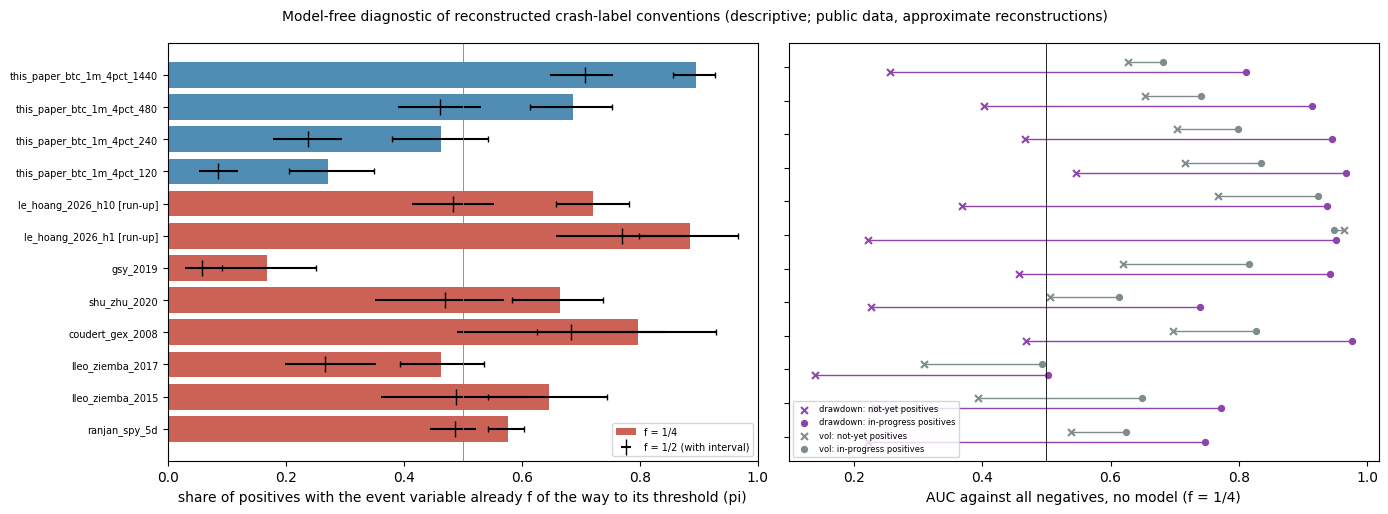

ranjan_spy_5d                pos 24.22% | pi 1/4 57.6% [54%, 60%] | 1/2 48.7% [44%, 52%] | drawdown AUC 0.524 (not-yet 0.222, in 0.747, bound yes) | realized volatility AUC 0.588 (not-yet 0.538, in 0.624, bound yes)
lleo_ziemba_2015             pos 31.47% | pi 1/4 64.7% [54%, 74%] | 1/2 48.9% [36%, 61%] | drawdown AUC 0.581 (not-yet 0.233, in 0.772, bound yes) | realized volatility AUC 0.559 (not-yet 0.394, in 0.649, bound yes)
lleo_ziemba_2017             pos 54.93% | pi 1/4 46.3% [39%, 54%] | 1/2 26.6% [20%, 35%] | drawdown AUC 0.308 (not-yet 0.140, in 0.503, bound no) | realized volatility AUC 0.395 (not-yet 0.309, in 0.494, bound no)
coudert_gex_2008             pos 15.04% | pi 1/4 79.7% [63%, 93%] | 1/2 68.3% [49%, 84%] | drawdown AUC 0.873 (not-yet 0.468, in 0.976, bound yes) | realized volatility AUC 0.801 (not-yet 0.697, in 0.827, bound yes)
shu_zhu_2020                 pos 18.64% | pi 1/4 66.5% [58%, 74%] | 1/2 46.9% [35%, 57%] | drawdown AUC 0.567 (not-yet 0.226, in 0.739, bo

In [5]:
LIT = AUD[~AUD.convention.str.startswith('this_paper')]; OWN = AUD[AUD.convention.str.startswith('this_paper')]
RANGE = []
for lab, d in [('reconstructed conventions (7 studies, 8 specifications)', LIT), ('this paper, crash window 2 to 24 hours', OWN)]:
    for tag, f in [('q', F_MAIN), ('h', F_ALT)]:
        if len(d):
            RANGE.append(dict(group=lab, f=f, pi_min=float(d[f'pi_{tag}'].min()), pi_max=float(d[f'pi_{tag}'].max()),
                              at_min=d.loc[d[f'pi_{tag}'].idxmin(), 'convention'], at_max=d.loc[d[f'pi_{tag}'].idxmax(), 'convention'],
                              n_lower_bound_ge_half=int((d[f'pi_{tag}_lo'] >= 0.5).sum()), rows=len(d)))
RNG = pd.DataFrame(RANGE); RNG.to_csv(OUT / '2_pi_range_by_definition.csv', index=False); display(RNG.round(3))

A = AUD.dropna(subset=['pi_q']).reset_index(drop=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
yy_ = np.arange(len(A)); own = A.convention.str.startswith('this_paper').to_numpy()
ax[0].barh(yy_, A.pi_q, color=np.where(own, '#2471a3', '#c0392b'), alpha=0.8, label='f = 1/4')
ax[0].errorbar(A.pi_q, yy_, xerr=[A.pi_q - A.pi_q_lo, A.pi_q_hi - A.pi_q], fmt='none', ecolor='k', capsize=2)
ax[0].errorbar(A.pi_h, yy_, xerr=[A.pi_h - A.pi_h_lo, A.pi_h_hi - A.pi_h], fmt='|', color='k', ms=12, capsize=0, label='f = 1/2 (with interval)')
ax[0].set_yticks(yy_); ax[0].set_yticklabels([f'{c} [run-up]' if 'le_hoang' in c else c for c in A.convention], fontsize=7); ax[0].set_xlim(0, 1)
ax[0].axvline(0.5, color='grey', lw=0.6); ax[0].legend(fontsize=7)
ax[0].set_xlabel('share of positives with the event variable already f of the way to its threshold (pi)')
for k, (col, mk) in enumerate([('drawdown', '#8e44ad'), ('vol', '#7f8c8d')]):
    off = -0.15 + 0.3 * k
    ax[1].hlines(yy_ + off, A[f'{col}_auc_not_yet'], A[f'{col}_auc_in_progress'], color=mk, lw=1)
    ax[1].scatter(A[f'{col}_auc_not_yet'], yy_ + off, color=mk, marker='x', s=25, label=f'{col}: not-yet positives')
    ax[1].scatter(A[f'{col}_auc_in_progress'], yy_ + off, color=mk, marker='o', s=18, label=f'{col}: in-progress positives')
ax[1].axvline(0.5, color='k', lw=0.6); ax[1].set_yticks(yy_); ax[1].set_yticklabels([]); ax[1].set_xlabel('AUC against all negatives, no model (f = 1/4)')
ax[1].legend(fontsize=6, loc='lower left')
plt.suptitle('Model-free diagnostic of reconstructed crash-label conventions (descriptive; public data, approximate reconstructions)', fontsize=10)
plt.tight_layout(); plt.savefig(OUT / '3_label_convention_diagnostic.png', dpi=140); plt.show()
(OUT / 'DIAGNOSTIC_SUMMARY.json').write_text(json.dumps(dict(spec_sha256=SPEC_SHA, status='descriptive, post hoc; label conventions reconstructed approximately; no study result evaluated',
                                                             manifest=MANI, rows=AUD.to_dict('records'), pi_range=RNG.to_dict('records')),
                                                        indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else (bool(o) if isinstance(o, np.bool_) else str(o))))
for r in A.to_dict('records'):
    print(f"{r['convention']:28s} pos {r['positive_rate']:6.2%} | pi 1/4 {r['pi_q']:5.1%} [{r['pi_q_lo']:.0%}, {r['pi_q_hi']:.0%}] | 1/2 {r['pi_h']:5.1%} [{r['pi_h_lo']:.0%}, {r['pi_h_hi']:.0%}]"
          f" | drawdown AUC {r['drawdown_auc']:.3f} (not-yet {r['drawdown_auc_not_yet']:.3f}, in {r['drawdown_auc_in_progress']:.3f}, bound {'yes' if r['drawdown_lb_conditions_hold'] else 'no'})"
          f" | {r['vol_score']} AUC {r['vol_auc']:.3f} (not-yet {r['vol_auc_not_yet']:.3f}, in {r['vol_auc_in_progress']:.3f}, bound {'yes' if r['vol_lb_conditions_hold'] else 'no'})")
for r in RNG.to_dict('records'):
    print(f"pi range, {r['group']}, f = {r['f']}: {r['pi_min']:.1%} ({r['at_min']}) to {r['pi_max']:.1%} ({r['at_max']}); lower bound >= 50% in {r['n_lower_bound_ge_half']} of {r['rows']}")

## Interpretation
- π(1/4), π(1/2): the share of positives at which the event variable has already covered at least 1/4 (or 1/2) of the distance to its threshold. I read the two together and do not write "most positives are in progress" when only one of them exceeds 50%.
- The `*_lb_conditions_hold` columns record whether π is a lower bound on the in-progress share of a score's skill, which holds only when its standard AUC is above 0.5 and its in-progress AUC is at least its pre-onset AUC; with `no`, π says nothing about where the skill comes from.
- Current-drawdown AUC: on pre-onset positives it lies well below 0.5 because the price is still near its high, so this score's signed contribution can exceed 100%; the table keeps both AUCs.
- VIX rows: "in progress" is a threshold run-up on days with VIX < 25, not detection after the event. When the VIX level's pre-onset AUC is at least its in-progress AUC, the skill comes from the level (proximity), not from the run-up path.
- This paper's rows (`this_paper_btc_1m_4pct_H`): I measure them with the same trailing-high rule; `pi_event_anchored` is the event-anchored value of notebook 22 that I use in the main decomposition. `2_pi_range_by_definition.csv` shows how far π moves when only the definition changes, next to the range across the literature rows.